# Bloco 4: Validação
**O instrumento mede o que diz medir? Com que erro?**

* 4.1 **Validade**: concordância com a amostra-ouro (acurácia, F1, kappa + IC)
* 4.2 **Onde erra**: matriz de confusão
* 4.3 **Viés diferencial**: o erro é igual entre campos políticos?
* 4.4 **Confiabilidade**: teste-reteste (sementes) e sensibilidade ao prompt
* 4.5 Concordância **humano × humano** (exercício em sala)

In [1]:
# === Configuração: funciona localmente e no Google Colab ===
import os, sys, subprocess
from pathlib import Path

# PROVISÓRIO: endereço do repositório público do minicurso (ajustar quando publicado)
REPO_URL = "https://github.com/jodavid/minicurso-ia-medicao"

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    if not Path("minicurso-ia-medicao").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    RAIZ = Path("minicurso-ia-medicao").resolve()
else:
    # localmente: a raiz é a pasta do minicurso (este notebook fica em python/)
    RAIZ = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()

os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "python"))
SAIDA = RAIZ / "resultados" / "python"          # o R grava em resultados/; o Python, aqui
(SAIDA / "figuras").mkdir(parents=True, exist_ok=True)
(SAIDA / "tabelas").mkdir(parents=True, exist_ok=True)
print("Raiz do projeto:", RAIZ)

Raiz do projeto: ~/minicurso_IA_medicao_publico


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from medicao import (CATEGORIAS, PALETA, COR_CAT, AZUIS, CINZA, CINZA_CLARO, CINZA_ESCURO, COR_EST, TINTA, TINTA2, GRADE, carrega_corpus, carrega_ouro,
                     carrega_llm, rotulo_run, resumo_metricas, boot_ic, alfa_krippendorff, estilo_graficos)
estilo_graficos()

corpus = carrega_corpus(RAIZ)
ouro = carrega_ouro(RAIZ)
llm = carrega_llm(RAIZ)
# Execuções oficiais do material: semente 42 (t=0) e 1–3 (t=0,8). Execuções extras
# (ex.: seu teste no notebook 03 com semente 7) aparecem como instrumentos à parte.
llm["instrumento"] = llm["run_id"].map(rotulo_run)

arq_base = SAIDA / "tabelas/predicoes_baselines.csv"      # gerado no notebook 02
if not arq_base.exists():
    arq_base = RAIZ / "dados/anotacoes/predicoes_baselines.csv"   # versão gerada pelo R
base_l = pd.read_csv(arq_base)

AVISO: a amostra-ouro ainda NÃO foi revisada por humanos (coluna `revisado`). Os resultados são ilustrativos.


## 4.1 Validade

In [3]:
aval = llm.merge(ouro[["doc_id", "categoria"]], on="doc_id")

linhas = []
for nome, v, p in [("Dicionário (regex)", base_l["categoria"], base_l["pred_dic"]),
                   ("TF-IDF + logística (CV 10)", base_l["categoria"], base_l["pred_ml"])]:
    li, ls = boot_ic(v, p)
    linhas.append({"instrumento": nome, **resumo_metricas(v, p), "kappa_li": li, "kappa_ls": ls})
for nome, d in aval.groupby("instrumento"):
    li, ls = boot_ic(d["categoria"], d["categoria_llm"])
    linhas.append({"instrumento": nome, **resumo_metricas(d["categoria"], d["categoria_llm"]),
                   "kappa_li": li, "kappa_ls": ls})
metricas = pd.DataFrame(linhas).sort_values("kappa", ascending=False).reset_index(drop=True)
metricas.to_csv(SAIDA / "tabelas/validade_instrumentos.csv", index=False)
metricas.round(3)

,instrumento,n,falhas_formato,acuracia,f1_macro,kappa,kappa_li,kappa_ls
0,LLM v2 (t=0),120,0.0,0.850,0.788,0.753,0.634,0.852
1,LLM v3 (t=0),120,0.0,0.842,0.793,0.750,0.636,0.851
2,"LLM v2 (t=0.8, s=1)",120,0.0,0.833,0.757,0.727,0.609,0.830
3,"LLM v2 (t=0.8, s=2)",120,0.0,0.833,0.757,0.727,0.609,0.830
4,"LLM v2 (t=0.8, s=3)",120,0.0,0.833,0.757,0.727,0.609,0.830
5,Dicionário (regex),120,0.0,0.808,0.782,0.699,0.587,0.804
6,LLM v1 (t=0),120,0.0,0.725,0.551,0.524,0.387,0.652
7,TF-IDF + logística (CV 10),120,0.0,0.725,0.565,0.508,0.370,0.632


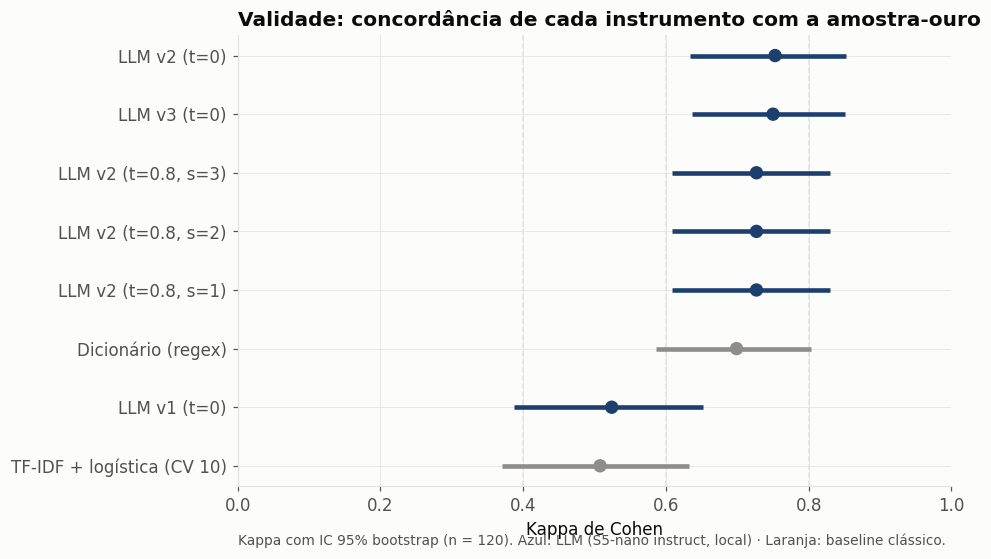

In [4]:
m = metricas.sort_values("kappa")
cores = [AZUIS[2] if i.startswith("LLM") else CINZA for i in m["instrumento"]]
fig, ax = plt.subplots(figsize=(9, 0.45 * len(m) + 1.6))
for x in (.4, .6, .8):
    ax.axvline(x, color=GRADE, ls="--", lw=1)
ax.hlines(m["instrumento"], m["kappa_li"], m["kappa_ls"], colors=cores, lw=3)
ax.scatter(m["kappa"], m["instrumento"], color=cores, s=60, zorder=3)
ax.set_xlim(0, 1); ax.set_xlabel("Kappa de Cohen")
ax.set_title("Validade: concordância de cada instrumento com a amostra-ouro")
ax.text(0, -0.13, "Kappa com IC 95% bootstrap (n = 120). Azul: LLM (S5-nano instruct, local) · Laranja: baseline clássico.",
        transform=ax.transAxes, color=TINTA2, fontsize=9)
fig.tight_layout(); fig.savefig(SAIDA / "figuras/01_validade_kappa.png", dpi=200)

## 4.2 Matriz de confusão do melhor LLM com temperatura 0

llm,PUNIR,REGULAR,PROMOVER,OUTRO
humano,,,,
PUNIR,22,0,0,0
REGULAR,4,61,4,0
PROMOVER,0,2,13,1
OUTRO,0,5,2,6


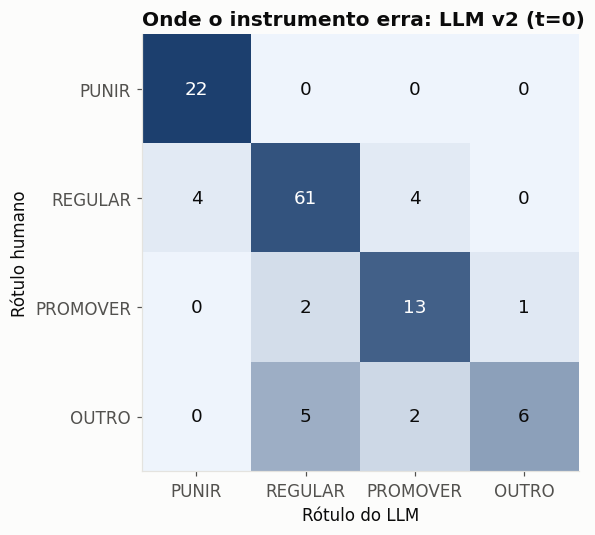

In [5]:
llm_t0 = metricas[metricas["instrumento"].str.contains(r"t=0\)")]
melhor = llm_t0.iloc[0]["instrumento"]
d = aval[aval["instrumento"] == melhor].copy()
d["categoria_llm"] = d["categoria_llm"].fillna("(falha)")
colunas = CATEGORIAS + (["(falha)"] if (d["categoria_llm"] == "(falha)").any() else [])
conf = pd.crosstab(pd.Categorical(d["categoria"], CATEGORIAS), pd.Categorical(d["categoria_llm"], colunas),
                   rownames=["humano"], colnames=["llm"], dropna=False)
prop = conf.div(conf.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.imshow(prop.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("azul", ["#eef4fc", AZUIS[2]]), vmin=0, vmax=1)
for i in range(conf.shape[0]):
    for j in range(conf.shape[1]):
        ax.text(j, i, conf.values[i, j], ha="center", va="center",
                color="white" if prop.values[i, j] > .5 else TINTA, fontsize=12)
ax.set_xticks(range(len(colunas)), colunas); ax.set_yticks(range(len(CATEGORIAS)), CATEGORIAS)
ax.set_xlabel("Rótulo do LLM"); ax.set_ylabel("Rótulo humano"); ax.grid(False)
ax.set_title(f"Onde o instrumento erra: {melhor}")
fig.tight_layout(); fig.savefig(SAIDA / "figuras/02_matriz_confusao.png", dpi=200)
conf

## 4.3 Viés diferencial

Pergunta: o LLM erra mais para um campo político? Se sim, comparações entre campos feitas com rótulos do LLM estarão enviesadas, **mesmo com acurácia alta**.

In [6]:
dif = d.merge(corpus[["doc_id", "campo", "casa"]], on="doc_id")
dif["acerto"] = dif["categoria"] == dif["categoria_llm"]
dif["punir_h"] = dif["categoria"] == "PUNIR"
dif["punir_l"] = dif["categoria_llm"] == "PUNIR"
dif = dif[dif["campo"] != "Sem partido/Outro"]

vies = dif.groupby("campo").agg(n=("acerto", "size"), acuracia=("acerto", "mean"),
                                prop_punir_humano=("punir_h", "mean"), prop_punir_llm=("punir_l", "mean"))
vies["vies_punir"] = vies["prop_punir_llm"] - vies["prop_punir_humano"]
vies["ep"] = np.sqrt(vies["acuracia"] * (1 - vies["acuracia"]) / vies["n"])
vies["li"], vies["ls"] = vies["acuracia"] - 1.96 * vies["ep"], vies["acuracia"] + 1.96 * vies["ep"]
vies.to_csv(SAIDA / "tabelas/vies_diferencial_campo.csv")

# Teste formal: o acerto depende do campo? (qui-quadrado; no R usamos regressão logística)
qui = chi2_contingency(pd.crosstab(dif["campo"], dif["acerto"]))
print(f"Qui-quadrado = {qui.statistic:.2f}, gl = {qui.dof}, p = {qui.pvalue:.3f}")
vies.round(3)

Qui-quadrado = 1.51, gl = 2, p = 0.469


,n,acuracia,prop_punir_humano,prop_punir_llm,vies_punir,ep,li,ls
campo,,,,,,,,
Centro,31,0.806,0.161,0.194,0.032,0.071,0.667,0.946
Direita,52,0.827,0.154,0.192,0.038,0.052,0.724,0.930
Esquerda,33,0.909,0.182,0.212,0.030,0.050,0.811,1.007


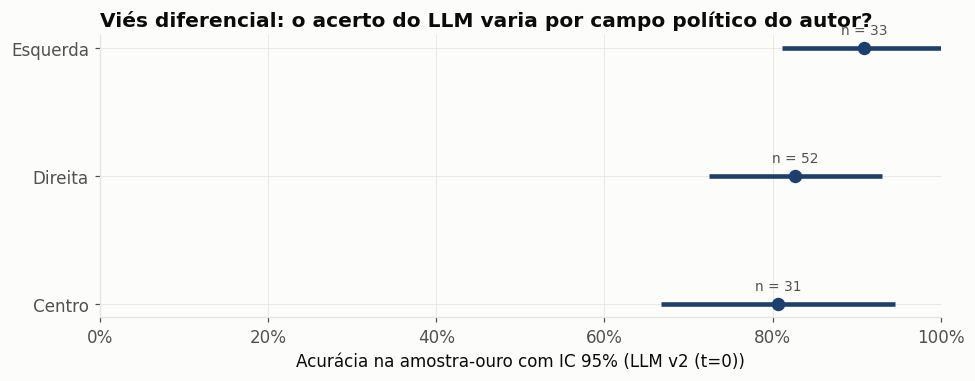

In [7]:
v = vies.sort_values("acuracia")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hlines(v.index, v["li"].clip(0), v["ls"].clip(upper=1), color=AZUIS[2], lw=3)
ax.scatter(v["acuracia"], v.index, color=AZUIS[2], s=60, zorder=3)
for campo, r in v.iterrows():
    ax.annotate(f"n = {int(r.n)}", (r.acuracia, campo), xytext=(0, 9), textcoords="offset points",
                ha="center", color=TINTA2, fontsize=9)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Viés diferencial: o acerto do LLM varia por campo político do autor?")
ax.set_xlabel(f"Acurácia na amostra-ouro com IC 95% ({melhor})")
fig.tight_layout(); fig.savefig(SAIDA / "figuras/03_vies_diferencial.png", dpi=200)

## 4.4 Confiabilidade

**(a) Teste-reteste:** mesmo prompt (v2), temperatura 0,8, três sementes. Não precisa de rótulo humano: mede só a estabilidade do instrumento.

**(b) Sensibilidade ao prompt:** v1, v2 e v3 com temperatura 0.

Confiabilidade não é validade: um instrumento pode ser perfeitamente estável e sistematicamente errado.

In [8]:
def instabilidade(largo):
    return np.mean([len(set(x.dropna())) > 1 for _, x in largo.iterrows()])

largo_seed = (llm[(llm["prompt_id"] == "v2") & (llm["temperatura"] > 0)]
              .pivot(index="doc_id", columns="semente", values="categoria_llm"))
largo_prompt = (llm[(llm["temperatura"] == 0) & (llm["semente"] == 42)]
                .pivot(index="doc_id", columns="prompt_id", values="categoria_llm"))

linhas = []
if largo_seed.shape[1] >= 2:
    linhas.append(dict(comparacao="Teste-reteste (v2, t=0,8, sementes)", n_execucoes=largo_seed.shape[1],
                       alfa_krippendorff=alfa_krippendorff(largo_seed),
                       prop_ementas_que_mudam=instabilidade(largo_seed)))
if largo_prompt.shape[1] >= 2:
    linhas.append(dict(comparacao="Sensibilidade ao prompt (t=0)", n_execucoes=largo_prompt.shape[1],
                       alfa_krippendorff=alfa_krippendorff(largo_prompt),
                       prop_ementas_que_mudam=instabilidade(largo_prompt)))
confiab = pd.DataFrame(linhas)
confiab.to_csv(SAIDA / "tabelas/confiabilidade.csv", index=False)
confiab.round(3)

,comparacao,n_execucoes,alfa_krippendorff,prop_ementas_que_mudam
0,"Teste-reteste (v2, t=0,8, sementes)",3,1.000,0.000
1,Sensibilidade ao prompt (t=0),3,0.746,0.234


cat,PUNIR,REGULAR,PROMOVER,OUTRO
prompt_id,,,,
v1,0.204,0.632,0.155,0.010
v2,0.230,0.516,0.191,0.062
v3,0.224,0.490,0.207,0.079
Referência\nhumana,0.174,0.493,0.184,0.148


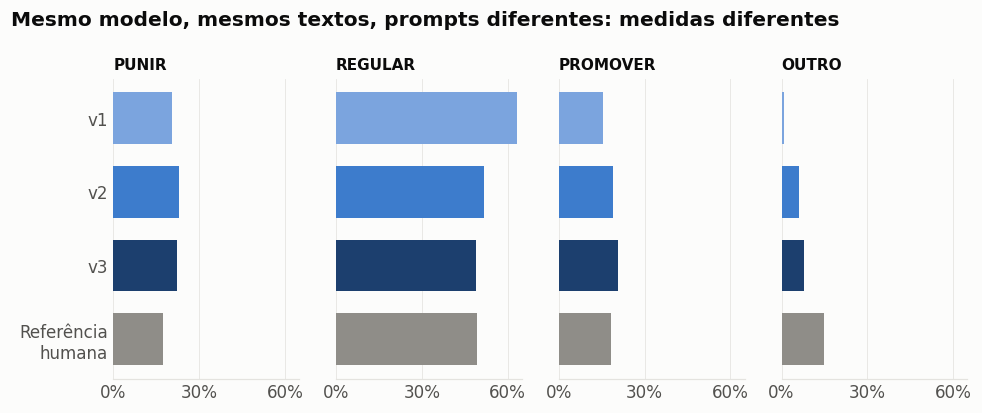

In [9]:
ref = pd.read_csv(RAIZ / "dados/anotacoes/referencia_completa.csv")
dist = (llm[(llm["temperatura"] == 0) & (llm["semente"] == 42)].assign(cat=lambda x: x["categoria_llm"].fillna("(falha)"))
        .groupby("prompt_id")["cat"].value_counts(normalize=True).unstack(fill_value=0))
dist.loc["Referência\nhumana"] = ref["categoria"].value_counts(normalize=True)
dist = dist.fillna(0)[[c for c in CATEGORIAS + ["(falha)"] if c in dist.columns]]

# Um painel por categoria: cada prompt (azuis, do v1 claro ao v3 escuro) contra a referência humana (cinza)
dist = dist.loc[:, (dist > 0).any()]
cores_fonte = [AZUIS[0], AZUIS[1], AZUIS[2], CINZA]
fig, axs = plt.subplots(1, dist.shape[1], figsize=(9, 3.8), sharey=True, sharex=True)
for ax, c in zip(axs, dist.columns):
    ax.barh(dist.index[::-1], dist[c].values[::-1], color=cores_fonte[::-1], height=.7)
    ax.set_title(c, loc="left", fontsize=10, fontweight="bold")
    ax.set_xticks([0, .3, .6]); ax.set_xlim(0, .65)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.grid(axis="y", visible=False)
    for lado in ("top", "right", "left"): ax.spines[lado].set_visible(False)
    ax.set_axisbelow(True); ax.tick_params(length=0)
fig.suptitle("Mesmo modelo, mesmos textos, prompts diferentes: medidas diferentes", x=.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(SAIDA / "figuras/04_sensibilidade_prompt.png", dpi=200)
dist.round(3)

### Variável eleitoral

In [10]:
ele = llm[(llm["temperatura"] == 0) & (llm["semente"] == 42)].merge(ouro[["doc_id", "eleitoral"]], on="doc_id")
ele["eleitoral_llm"] = ele["eleitoral_llm"].astype("boolean")
tab = ele.groupby("prompt_id").apply(lambda g: pd.Series(dict(
    n_eleitoral_humano=int(g["eleitoral"].sum()),
    n_eleitoral_llm=int(g["eleitoral_llm"].fillna(False).sum()),
    sensibilidade=g.loc[g["eleitoral"] == 1, "eleitoral_llm"].mean(),
    especificidade=(~g.loc[g["eleitoral"] == 0, "eleitoral_llm"]).mean())))
tab.to_csv(SAIDA / "tabelas/validade_eleitoral.csv")
tab

,n_eleitoral_humano,n_eleitoral_llm,sensibilidade,especificidade
prompt_id,,,,
v1,8.0,8.0,1.0,1.0
v2,8.0,8.0,1.0,1.0
v3,8.0,8.0,1.0,1.0


## 4.5 Humano × humano (exercício em sala)

Cada participante preenche `material_apoio/exercicio_codificacao.csv` e salva como `material_apoio/respostas/<nome>.csv`. Aqui calculamos o alfa entre os humanos, para comparar com o alfa LLM × referência nas mesmas 20 ementas.

In [11]:
arqs = sorted((RAIZ / "material_apoio/respostas").glob("*.csv"))
if len(arqs) >= 2:
    resp = pd.concat([pd.read_csv(a).assign(codificador=a.stem) for a in arqs])
    resp["categoria"] = resp["categoria"].str.strip().str.upper()
    m = resp.pivot(index="doc_id", columns="codificador", values="categoria")
    print(f"Alfa de Krippendorff entre {len(arqs)} codificadores humanos: {alfa_krippendorff(m):.3f}")
else:
    print("Ainda não há respostas suficientes em material_apoio/respostas/ (mínimo: 2).")

Ainda não há respostas suficientes em material_apoio/respostas/ (mínimo: 2).
